In [1]:
import hashlib
import os
import urllib.request
import zipfile
from pathlib import Path

import pandas as pd

seed=42
root=Path.cwd()
data_dir=root / "data"
data_dir.mkdir(parents=True, exist_ok=True)
zip_path=data_dir / "banana_ripeness_dataset.zip"
extract_dir=data_dir / "banana_ripeness"
manifest_path=data_dir / "banana_image_manifest.csv"
zip_url=(
    "https://huggingface.co/datasets/Sapek007/banana-ripeness/resolve/"
    "1ae50a4e9ffa7c026dfcea4daf7df88b06770b5c/"
    "banana_ripeness_dataset.zip?download=true"
)
zip_sha256="2b12641883bbf13e782727e3deb9a3bf141a26fecb832bc045e508e319014567"

if not zip_path.is_file():
    temp_path=zip_path.with_suffix(".zip.part")
    urllib.request.urlretrieve(zip_url, temp_path)
    temp_path.replace(zip_path)

sha=hashlib.sha256()
with zip_path.open("rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        sha.update(chunk)
if sha.hexdigest() != zip_sha256:
    raise ValueError("The downloaded banana dataset did not match its pinned SHA-256.")

split_names=("train", "valid", "test")
if not all((extract_dir / name).is_dir() for name in split_names):
    extract_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
        for item in archive.infolist():
            target=(extract_dir / item.filename).resolve()
            if os.path.commonpath([str(extract_dir.resolve()), str(target)]) != str(extract_dir.resolve()):
                raise ValueError(f"Unsafe path in dataset archive: {item.filename}")
        archive.extractall(extract_dir)

split_root=extract_dir
if not all((split_root / name).is_dir() for name in split_names):
    raise FileNotFoundError("Expected train, valid, and test image folders in the dataset archive.")
print("Dataset archive:", zip_path)
print("Image folders:", extract_dir)

Dataset archive: D:\ML\Projects\RetailPriceForecast\data\banana_ripeness_dataset.zip
Image folders: D:\ML\Projects\RetailPriceForecast\data\banana_ripeness


In [2]:
from PIL import Image

label_names=("overripe", "ripe", "rotten", "unripe")
image_rows=[]
image_exts={".jpg", ".jpeg", ".png", ".bmp", ".webp"}
for split in split_names:
    for label in label_names:
        folder=split_root / split / label
        if not folder.is_dir():
            raise FileNotFoundError(f"Missing image class folder: {folder}")
        for image_path in sorted(folder.iterdir()):
            if image_path.is_file() and image_path.suffix.lower() in image_exts:
                image_rows.append({
                    "image_path": str(image_path.relative_to(root)),
                    "label": label,
                    "split": split,
                })

manifest=pd.DataFrame(image_rows)
if manifest.empty or set(manifest["label"]) != set(label_names):
    raise ValueError("The dataset must contain images for all four ripeness classes.")
manifest.to_csv(manifest_path, index=False)
print("Total labeled images:", f"{len(manifest):,}")
print("Saved image manifest:", manifest_path)
print(manifest.groupby(["split", "label"]).size().unstack(fill_value=0).to_string())
print("\nManifest preview:")
print(manifest.head().to_string(index=False))

Total labeled images: 13,478
Saved image manifest: D:\ML\Projects\RetailPriceForecast\data\banana_image_manifest.csv
label  overripe  ripe  rotten  unripe
split                                
test        113   154     185     110
train      2349  3522    4020    1902
valid       229   339     388     167

Manifest preview:
                                                                                                                              image_path    label split
data\banana_ripeness\train\overripe\musa-acuminata-mold-e17eb046-1d0a-11ec-a49d-d8c4975e38aa_jpg.rf.344f0fa4428c43f28dd642286964263f.jpg overripe train
data\banana_ripeness\train\overripe\musa-acuminata-mold-e17eb046-1d0a-11ec-a49d-d8c4975e38aa_jpg.rf.82add51d9e4cb5a068c0661cc63ba5d3.jpg overripe train
data\banana_ripeness\train\overripe\musa-acuminata-mold-e17eb046-1d0a-11ec-a49d-d8c4975e38aa_jpg.rf.c01b5d4fddf6b1943a2c6f57f6cbdbaf.jpg overripe train
data\banana_ripeness\train\overripe\musa-acuminata-mold-e18838c1-1

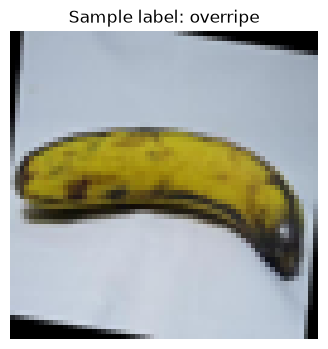

In [3]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset

from banana_classifier import IMAGE_SIZE, banana_cnn, image_tensor

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(min(4, os.cpu_count() or 1))
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

class banana_images(Dataset):
    def __init__(self, rows, augment=False):
        self.rows=rows.reset_index(drop=True)
        self.augment=augment

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row=self.rows.iloc[index]
        with Image.open(root / row["image_path"]) as image:
            image=image.convert("RGB")
            if self.augment and random.random() < 0.5:
                image=image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            tensor=image_tensor(image)
        return tensor, label_names.index(row["label"])

train_rows=manifest.loc[manifest["split"] == "train"]
valid_rows=manifest.loc[manifest["split"] == "valid"]
test_rows=manifest.loc[manifest["split"] == "test"]
train_ds=banana_images(train_rows, augment=True)
valid_ds=banana_images(valid_rows)
test_ds=banana_images(test_rows)
train_dl=DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)
valid_dl=DataLoader(valid_ds, batch_size=128, shuffle=False, num_workers=0)
test_dl=DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=0)

sample_image, sample_label=train_ds[0]
plt.figure(figsize=(4, 4))
plt.imshow(np.clip(sample_image.permute(1, 2, 0).numpy() * 0.5 + 0.5, 0, 1))
plt.title(f"Sample label: {label_names[sample_label]}")
plt.axis("off");

In [4]:
import copy
import torch.nn as nn

model=banana_cnn().to(device)
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)
epochs=5
patience=2
best_acc=0.0
best_state=None
stale=0
history=[]

for epoch in range(epochs):
    model.train()
    train_loss=0.0
    for batch_x, batch_y in train_dl:
        batch_x=batch_x.to(device)
        batch_y=batch_y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits=model(batch_x)
        loss=loss_fn(logits, batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(batch_y)

    model.eval()
    valid_ok=0
    with torch.inference_mode():
        for batch_x, batch_y in valid_dl:
            logits=model(batch_x.to(device))
            valid_ok += int((logits.argmax(dim=1).cpu() == batch_y).sum())
    train_loss /= len(train_ds)
    valid_acc=valid_ok / len(valid_ds)
    history.append({"epoch": epoch + 1, "train_loss": train_loss, "valid_accuracy": valid_acc})
    print(f"Epoch {epoch + 1}: train loss={train_loss:.4f}, validation accuracy={valid_acc:.4f}")

    if valid_acc > best_acc:
        best_acc=valid_acc
        best_state=copy.deepcopy(model.state_dict())
        stale=0
    else:
        stale += 1
        if stale >= patience:
            print("Early stopping: validation accuracy did not improve.")
            break

if best_state is None:
    raise RuntimeError("Training did not produce a valid model checkpoint.")
model.load_state_dict(best_state)
model.eval()
print(f"Best validation accuracy: {best_acc:.4f}")

Epoch 1: train loss=0.4732, validation accuracy=0.8851


Epoch 2: train loss=0.2786, validation accuracy=0.8896


Epoch 3: train loss=0.2382, validation accuracy=0.9323


Epoch 4: train loss=0.2080, validation accuracy=0.9332


Epoch 5: train loss=0.1824, validation accuracy=0.9305
Best validation accuracy: 0.9332


Held-out test accuracy: 0.9181
              precision    recall  f1-score   support

    overripe       0.84      0.95      0.89       113
        ripe       0.94      0.88      0.91       154
      rotten       0.92      0.93      0.93       185
      unripe       0.97      0.92      0.94       110

    accuracy                           0.92       562
   macro avg       0.92      0.92      0.92       562
weighted avg       0.92      0.92      0.92       562



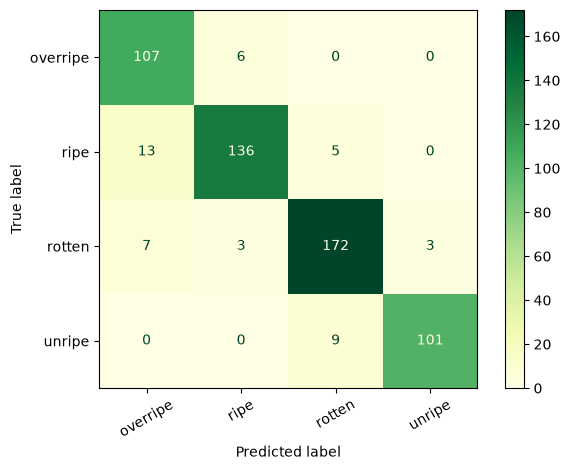

Saved image model: D:\ML\Projects\RetailPriceForecast\banana_model.pt


In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

true_ids=[]
pred_ids=[]
with torch.inference_mode():
    for batch_x, batch_y in test_dl:
        pred_ids.extend(model(batch_x.to(device)).argmax(dim=1).cpu().tolist())
        true_ids.extend(batch_y.tolist())

test_acc=accuracy_score(true_ids, pred_ids)
print(f"Held-out test accuracy: {test_acc:.4f}")
print(classification_report(true_ids, pred_ids, target_names=label_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    true_ids,
    pred_ids,
    display_labels=label_names,
    xticks_rotation=30,
    cmap="YlGn",
);
plt.tight_layout()
plt.show()

model_path=root / "banana_model.pt"
torch.save({
    "state_dict": model.cpu().state_dict(),
    "labels": list(label_names),
    "image_size": IMAGE_SIZE,
    "validation_accuracy": best_acc,
    "test_accuracy": test_acc,
    "training_images": len(train_ds),
    "seed": seed,
}, model_path)
print("Saved image model:", model_path)

In [6]:
from banana_classifier import predict_banana

sample_path=root / test_rows.iloc[0]["image_path"]
print("Test image:", sample_path)
print(predict_banana(sample_path))

Test image: D:\ML\Projects\RetailPriceForecast\data\banana_ripeness\test\overripe\musa-acuminata-mold-e18cfd23-1d0a-11ec-87d5-d8c4975e38aa_jpg.rf.175dccdf3479ad6a73213197efe00527.jpg
{'label': 'overripe', 'confidence': 0.9720036387443542, 'days_left': '0-1 day', 'warning': 'Ripeness class only; days are a rough room-temperature guide, not a measured expiry date. Storage conditions can change this; model confidence is not calibrated. Use banana-only images; other objects can be misclassified.'}
